# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Book Bestsellers Dataset](https://www.kaggle.com/datasets/vedauv/what-makes-a-book-a-bestseller-8000-books?select=book_bestsellers.csv)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('book_bestsellers.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,book_id,title,genre,publisher_type,format,publication_year,page_count,price_usd,author_prior_books,author_followers_k,...,series_book_number,movie_or_tv_deal,launch_marketing_usd_k,preorders_k,early_review_avg,social_mentions_k,copies_sold_k,goodreads_ratings_k,avg_rating,bestseller
0,B00001,Phantom Odyssey,Thriller,Self-published,eBook-first,2025,306,4.63,5,1.2,...,2,0,12.5,1.11,4.34,5.5,8.46,3.60,3.76,0
1,B00002,Crimson Echo,Mystery,Mid-size,Paperback,2025,445,17.92,1,12.1,...,0,0,6.1,4.36,3.51,2.9,13.12,5.86,3.55,0
2,B00003,Wild Tide,Business,Self-published,Paperback,2017,395,15.82,2,18.4,...,0,0,7.6,1.77,4.38,4.8,8.54,2.83,4.09,0
3,B00004,Rogue Frontier,Mystery,Indie press,Paperback,2018,455,17.27,6,22.2,...,0,0,4.1,2.65,3.54,5.6,8.77,3.62,3.75,0
4,B00005,Last Gate,Fantasy,Self-published,eBook-first,2010,394,4.50,0,17.6,...,0,0,10.2,2.70,3.62,1.3,6.38,1.19,3.89,0


## last Five row

In [4]:
df.tail()

,book_id,title,genre,publisher_type,format,publication_year,page_count,price_usd,author_prior_books,author_followers_k,...,series_book_number,movie_or_tv_deal,launch_marketing_usd_k,preorders_k,early_review_avg,social_mentions_k,copies_sold_k,goodreads_ratings_k,avg_rating,bestseller
7995,B07996,Frozen Horizon,Thriller,Indie press,Paperback,2023,430,19.87,6,8.8,...,0,0,7.5,1.96,3.94,4.1,3.14,1.63,3.69,0
7996,B07997,Brave Horizon,Young Adult,Mid-size,Hardcover,2014,414,13.66,5,20.4,...,0,1,12.7,1.55,3.92,2.5,18.46,4.71,3.93,0
7997,B07998,Lost Dawn,Thriller,Indie press,eBook-first,2010,357,7.54,4,42.0,...,4,0,6.4,2.93,4.22,16.8,44.66,10.88,4.22,0
7998,B07999,Golden Outpost,Thriller,Self-published,Hardcover,2019,436,12.94,5,32.4,...,2,0,5.5,1.08,3.66,15.0,7.77,2.09,3.97,0
7999,B08000,Hollow Frontier,Horror,Big Five,Hardcover,2015,244,12.91,2,4.6,...,0,0,15.3,1.01,4.09,10.3,30.90,10.04,3.80,0


## Shape of our dataset

In [5]:
df.shape

(8000, 21)

## List out all columns

In [6]:
df.columns

Index(['book_id', 'title', 'genre', 'publisher_type', 'format',
       'publication_year', 'page_count', 'price_usd', 'author_prior_books',
       'author_followers_k', 'is_series', 'series_book_number',
       'movie_or_tv_deal', 'launch_marketing_usd_k', 'preorders_k',
       'early_review_avg', 'social_mentions_k', 'copies_sold_k',
       'goodreads_ratings_k', 'avg_rating', 'bestseller'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

book_id                    object
title                      object
genre                      object
publisher_type             object
format                     object
publication_year            int64
page_count                  int64
price_usd                 float64
author_prior_books          int64
author_followers_k        float64
is_series                   int64
series_book_number          int64
movie_or_tv_deal            int64
launch_marketing_usd_k    float64
preorders_k               float64
early_review_avg          float64
social_mentions_k         float64
copies_sold_k             float64
goodreads_ratings_k       float64
avg_rating                float64
bestseller                  int64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   book_id                 8000 non-null   object 
 1   title                   8000 non-null   object 
 2   genre                   8000 non-null   object 
 3   publisher_type          8000 non-null   object 
 4   format                  8000 non-null   object 
 5   publication_year        8000 non-null   int64  
 6   page_count              8000 non-null   int64  
 7   price_usd               8000 non-null   float64
 8   author_prior_books      8000 non-null   int64  
 9   author_followers_k      8000 non-null   float64
 10  is_series               8000 non-null   int64  
 11  series_book_number      8000 non-null   int64  
 12  movie_or_tv_deal        8000 non-null   int64  
 13  launch_marketing_usd_k  8000 non-null   float64
 14  preorders_k             8000 non-null   

## Check Null Value

In [9]:
df.isnull().sum()

book_id                   0
title                     0
genre                     0
publisher_type            0
format                    0
publication_year          0
page_count                0
price_usd                 0
author_prior_books        0
author_followers_k        0
is_series                 0
series_book_number        0
movie_or_tv_deal          0
launch_marketing_usd_k    0
preorders_k               0
early_review_avg          0
social_mentions_k         0
copies_sold_k             0
goodreads_ratings_k       0
avg_rating                0
bestseller                0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,publication_year,page_count,price_usd,author_prior_books,author_followers_k,is_series,series_book_number,movie_or_tv_deal,launch_marketing_usd_k,preorders_k,early_review_avg,social_mentions_k,copies_sold_k,goodreads_ratings_k,avg_rating,bestseller
count,8000.000000,8000.00000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,2017.479125,338.83800,16.592121,3.457750,21.947425,0.372250,1.459625,0.038875,12.594812,1.943705,3.899468,7.567812,23.825829,10.538709,3.851600,0.100000
std,4.621578,90.39364,7.764806,2.057546,41.174863,0.483435,2.245718,0.193309,18.275081,2.390860,0.388818,10.277960,74.868948,38.823129,0.299481,0.300019
min,2010.000000,90.00000,2.990000,0.000000,0.100000,0.000000,0.000000,0.000000,0.200000,0.050000,2.420000,0.100000,0.010000,0.000000,2.740000,0.000000
25%,2014.000000,278.00000,9.920000,2.000000,4.200000,0.000000,0.000000,0.000000,3.500000,0.640000,3.630000,2.200000,2.140000,0.850000,3.650000,0.000000
50%,2017.000000,338.00000,16.660000,3.000000,10.000000,0.000000,0.000000,0.000000,6.900000,1.230000,3.900000,4.400000,6.365000,2.620000,3.850000,0.000000
75%,2021.000000,399.00000,23.250000,5.000000,23.200000,1.000000,3.000000,0.000000,14.525000,2.350000,4.170000,8.900000,19.240000,8.102500,4.060000,0.000000
max,2025.000000,734.00000,29.990000,15.000000,1142.900000,1.000000,7.000000,1.000000,397.600000,53.550000,5.000000,155.600000,2832.470000,1836.170000,4.900000,1.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

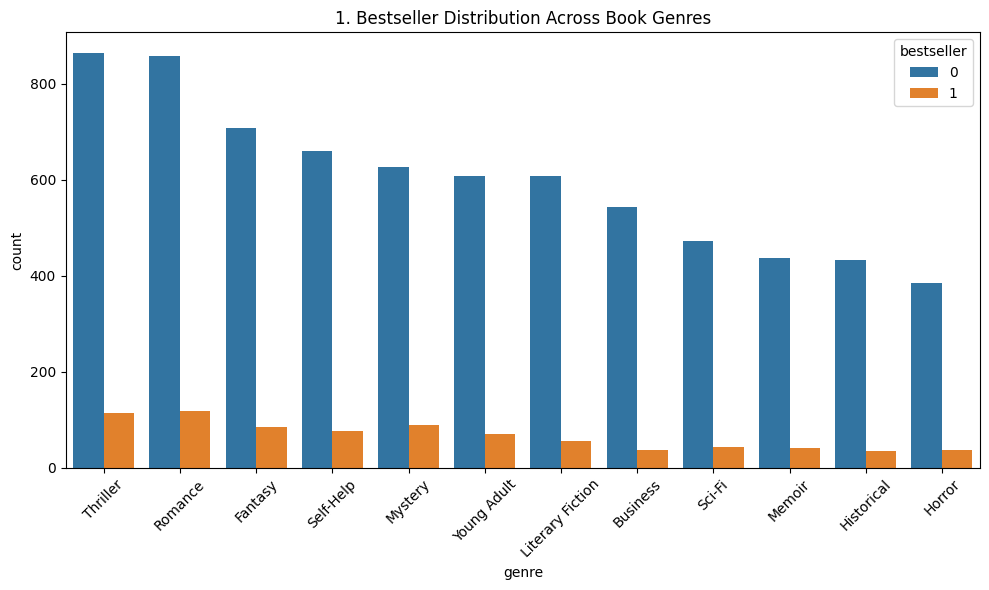

In [13]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='genre', hue='bestseller', order=df['genre'].value_counts().index)
plt.xticks(rotation=45)
plt.title(f'{plot_no}. Bestseller Distribution Across Book Genres')
show_fig()
plot_no += 1

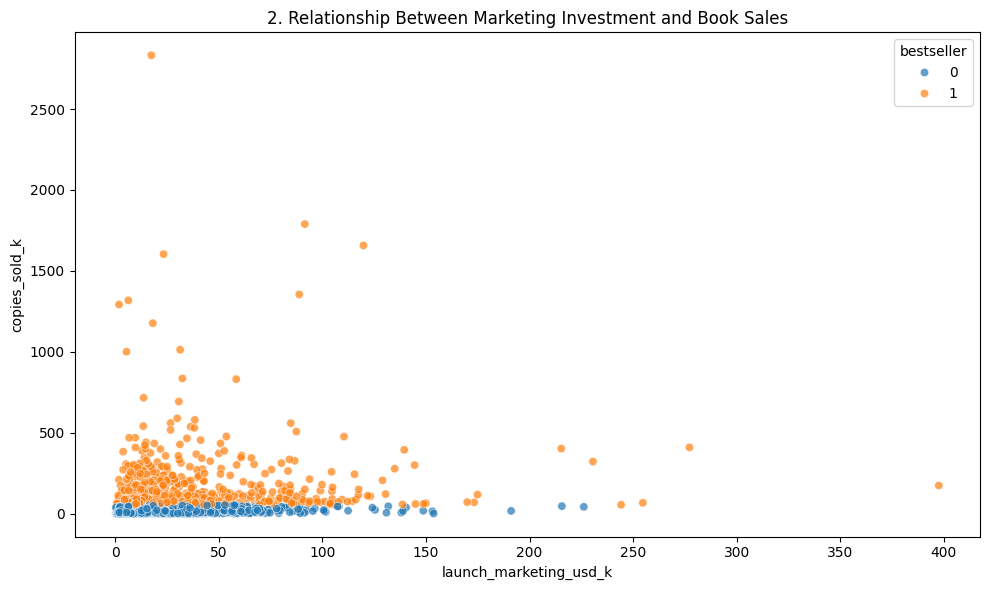

In [14]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='launch_marketing_usd_k', y='copies_sold_k', hue='bestseller', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Marketing Investment and Book Sales')
show_fig()
plot_no += 1

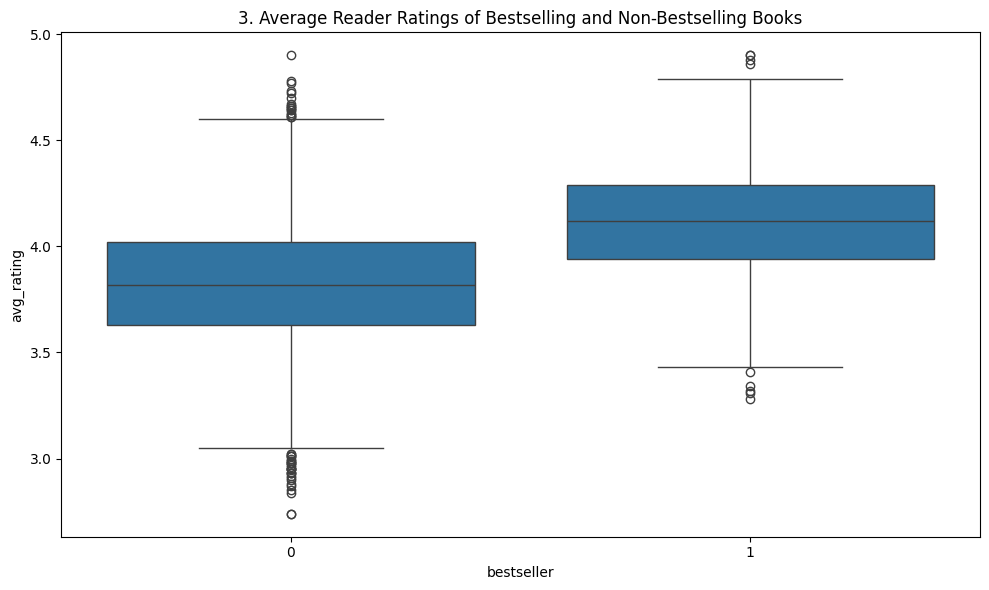

In [15]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='bestseller', y='avg_rating')
plt.title(f'{plot_no}. Average Reader Ratings of Bestselling and Non-Bestselling Books')
show_fig()
plot_no += 1

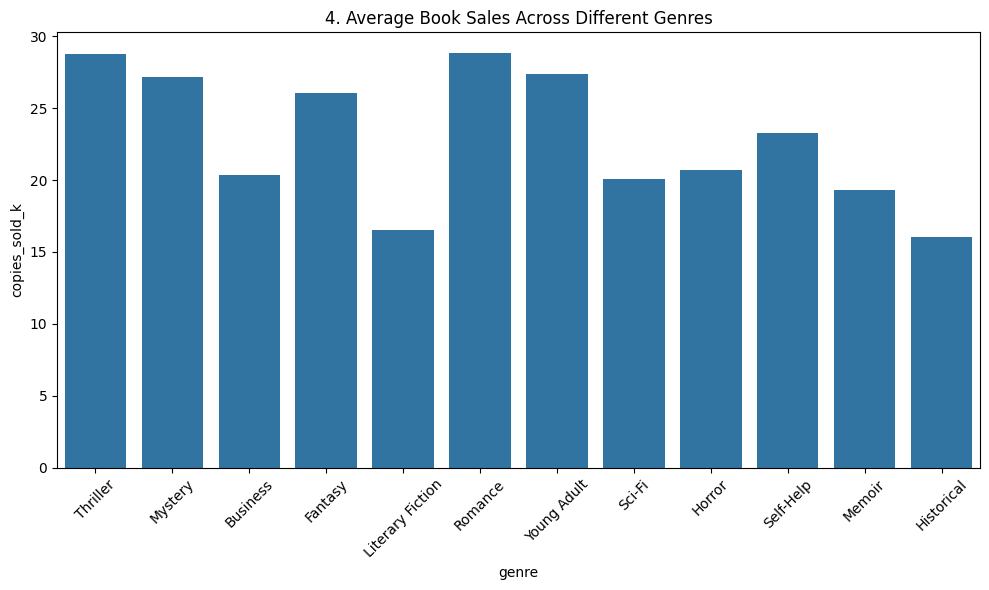

In [16]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='genre', y='copies_sold_k', estimator='mean', errorbar=None)
plt.xticks(rotation=45)
plt.title(f'{plot_no}. Average Book Sales Across Different Genres')
show_fig()
plot_no += 1

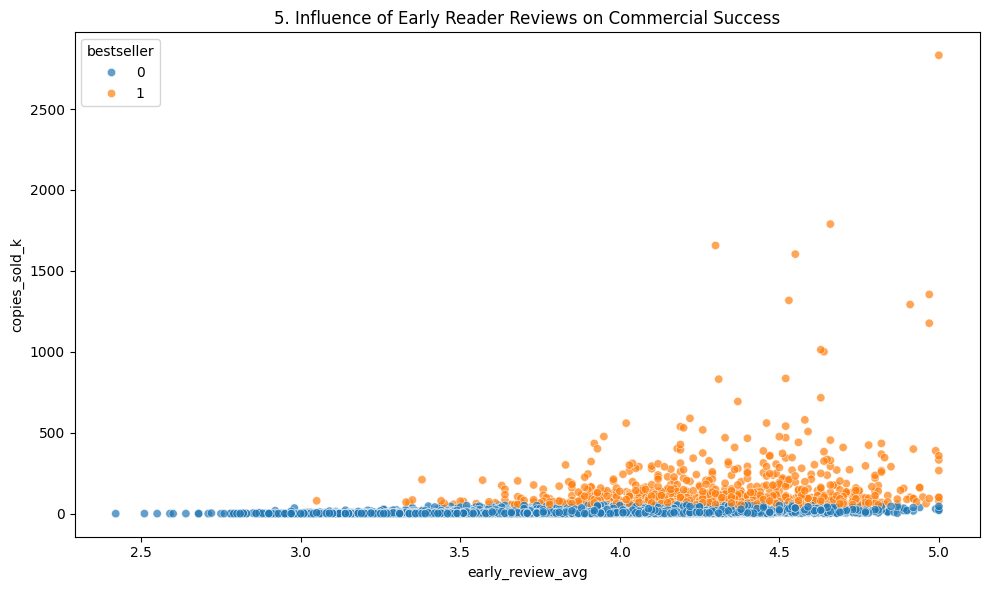

In [17]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='early_review_avg', y='copies_sold_k', hue='bestseller', alpha=0.7)
plt.title(f'{plot_no}. Influence of Early Reader Reviews on Commercial Success')
show_fig()
plot_no += 1

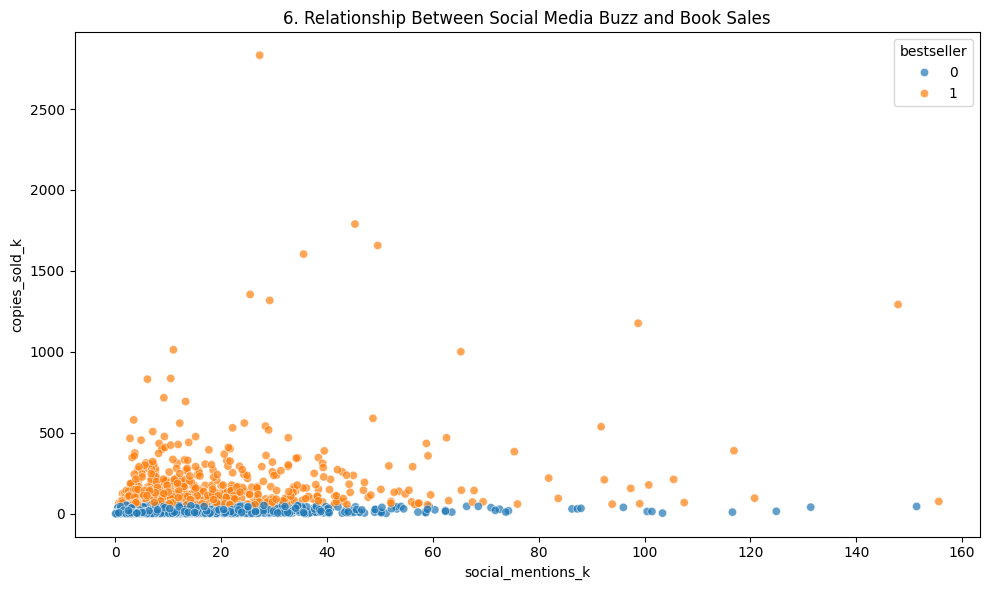

In [18]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='social_mentions_k', y='copies_sold_k', hue='bestseller', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Social Media Buzz and Book Sales')
show_fig()
plot_no += 1

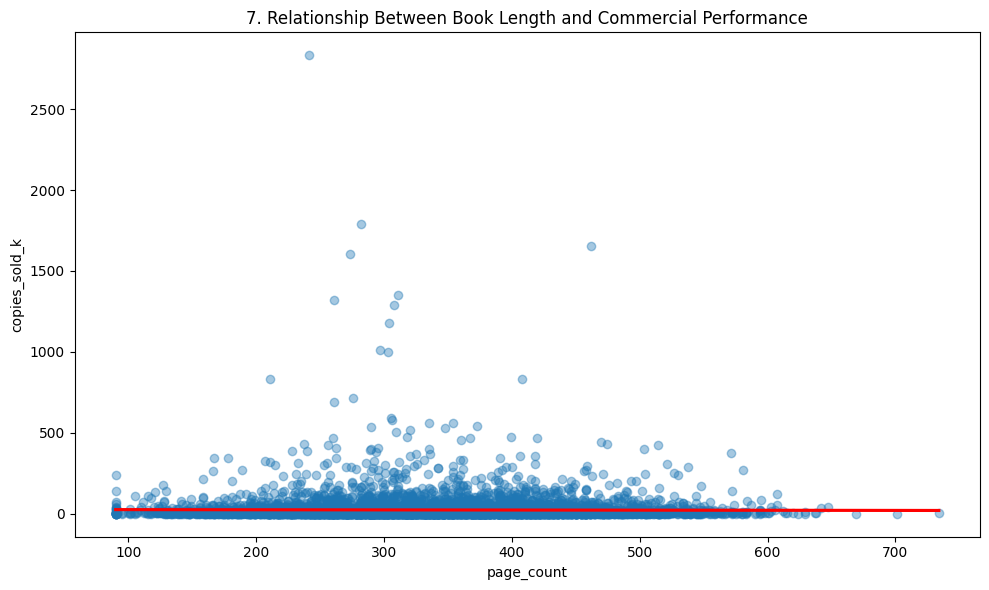

In [19]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='page_count', y='copies_sold_k', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Relationship Between Book Length and Commercial Performance')
show_fig()
plot_no += 1

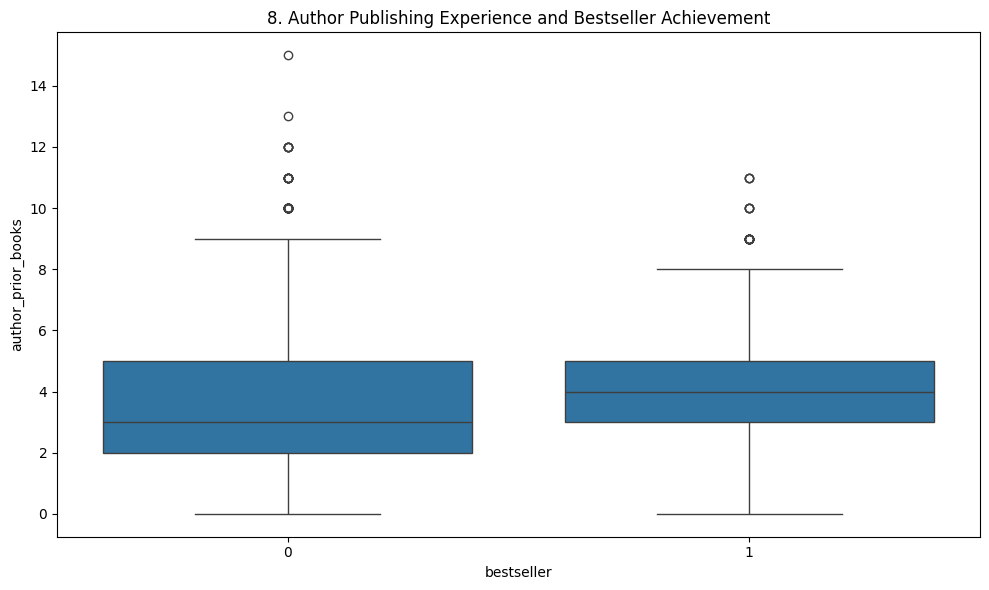

In [20]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='bestseller', y='author_prior_books')
plt.title(f'{plot_no}. Author Publishing Experience and Bestseller Achievement')
show_fig()
plot_no += 1

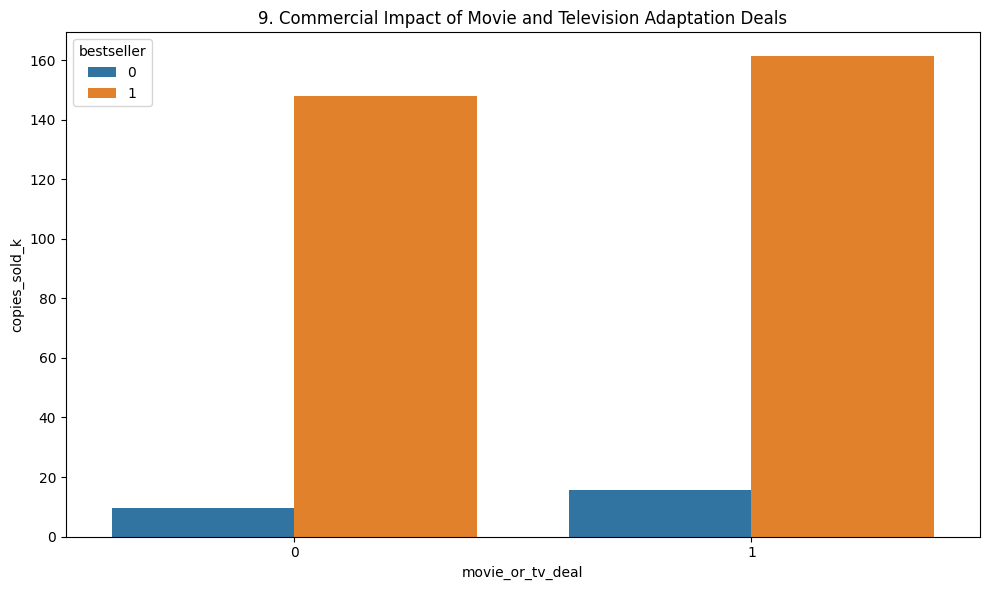

In [21]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='movie_or_tv_deal', y='copies_sold_k', hue='bestseller', errorbar=None)
plt.title(f'{plot_no}. Commercial Impact of Movie and Television Adaptation Deals')
show_fig()
plot_no += 1

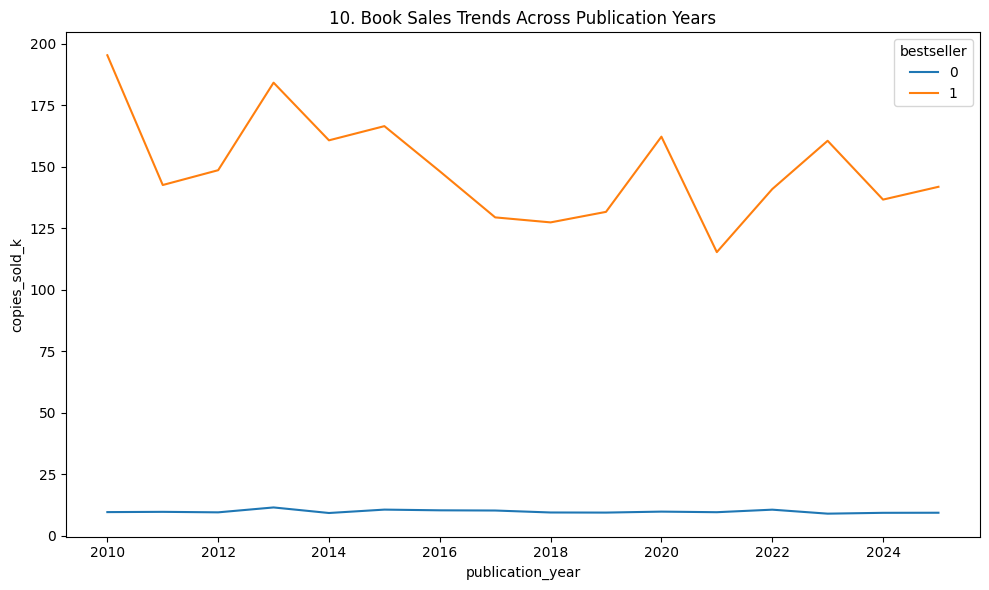

In [22]:
fig = plt.figure(figsize=(10,6))
sns.lineplot(data=df, x='publication_year', y='copies_sold_k', hue='bestseller', errorbar=None)
plt.title(f'{plot_no}. Book Sales Trends Across Publication Years')
show_fig()
plot_no += 1

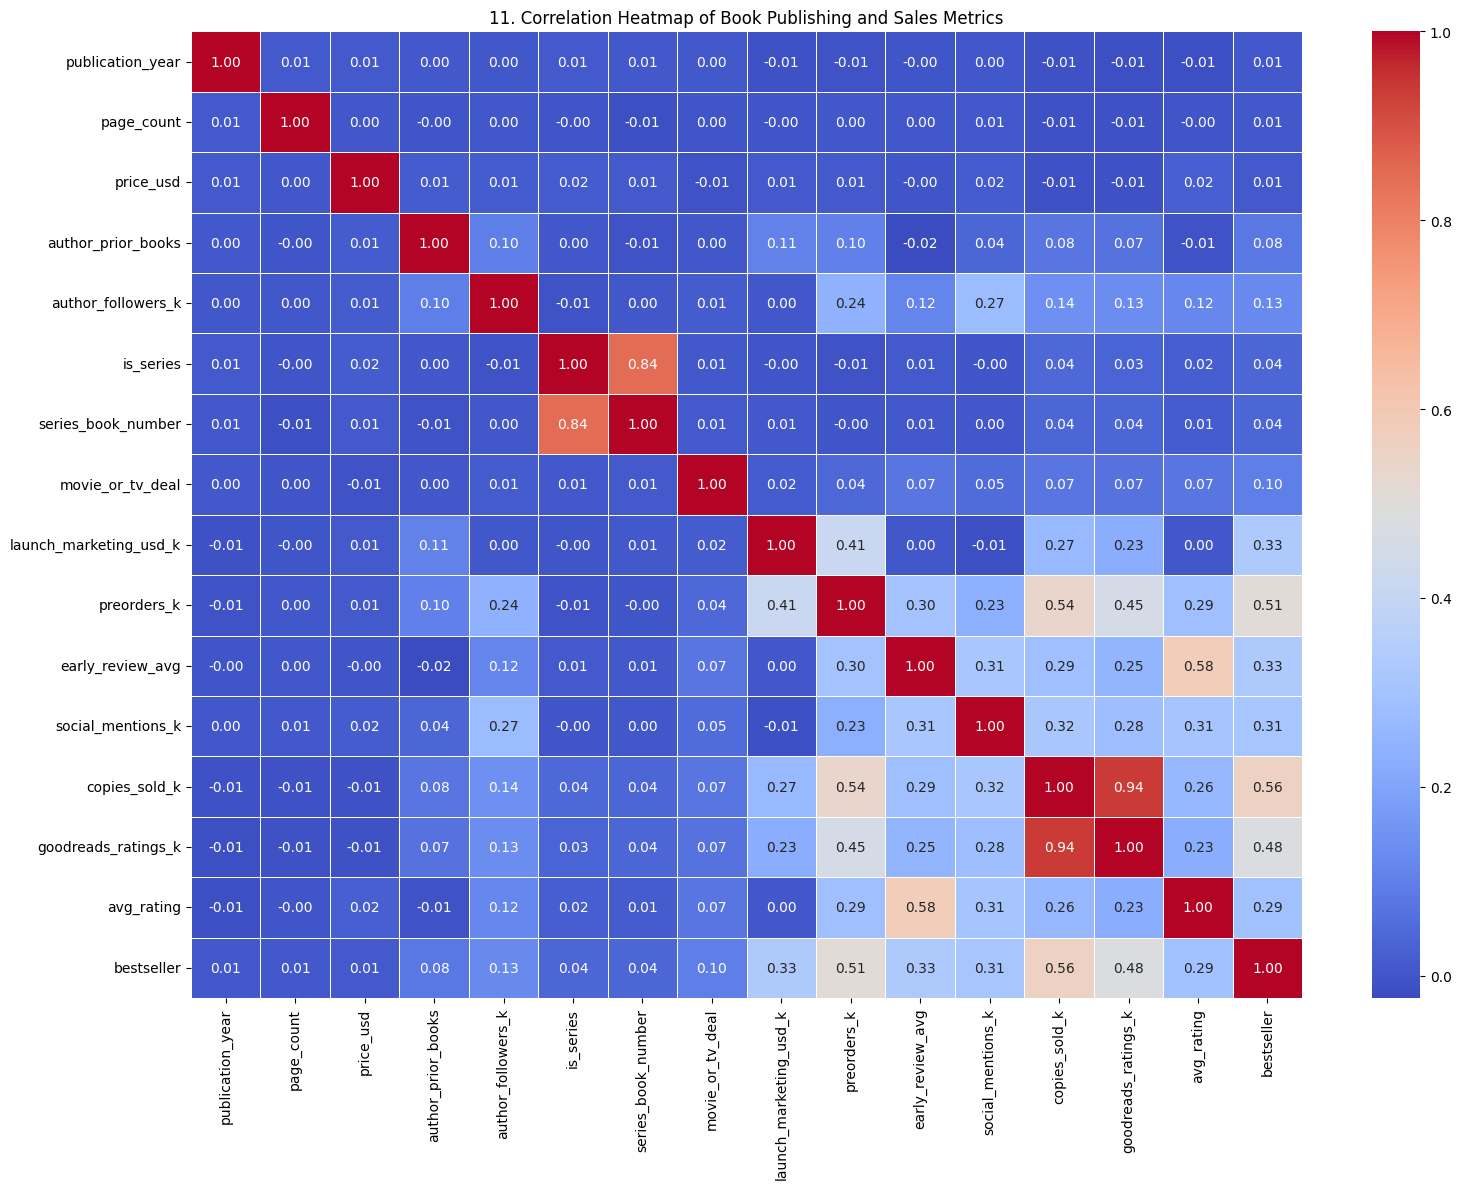

In [23]:
corr = df.select_dtypes(include='number').corr()
fig = plt.figure(figsize=(16,12))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Book Publishing and Sales Metrics')
show_fig()
plot_no += 1

# Model Training

## Separate features and target

In [24]:
X = df.drop(columns=['bestseller', 'book_id', 'title'], errors='ignore')
y = df['bestseller']

## Identify numerical and categorical columns

In [25]:
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

## Preprocess numerical and categorical features

In [26]:
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

## Create gradient boosting model

In [27]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=20,
        l2_regularization=2,
        random_state=42
    ))
])

## Split dataset into training and testing sets

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Train the model

In [29]:
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Make predictions

In [30]:
y_pred = model.predict(X_test)

## Evaluate model performance

In [31]:
accuracy = accuracy_score(y_test, y_pred)

print("Model: Hist Gradient Boosting Classifier")
print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy Percentage: {accuracy * 100:.2f}%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Model: Hist Gradient Boosting Classifier
Accuracy: 0.9981
Accuracy Percentage: 99.81%

Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1440
           1       0.99      0.99      0.99       160

    accuracy                           1.00      1600
   macro avg       1.00      0.99      0.99      1600
weighted avg       1.00      1.00      1.00      1600



## Plot confusion matrix

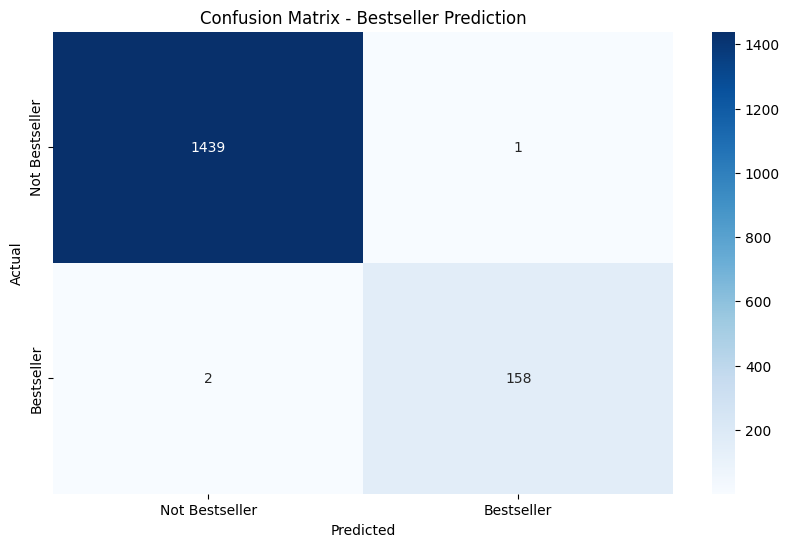

In [32]:
fig = plt.figure(figsize=(10,6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Bestseller', 'Bestseller'],
            yticklabels=['Not Bestseller', 'Bestseller'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Bestseller Prediction')
plt.show()